In [2]:
from pathlib import Path
import importlib.util
import shutil
import subprocess
import sys
import tempfile

CURRENT_DIR = Path.cwd().resolve()
PROJECT_DIR = next(
    (folder for folder in [CURRENT_DIR, *CURRENT_DIR.parents]
     if (folder / "notebooks").is_dir() and (folder / "src").is_dir()),
    CURRENT_DIR
)

DATA_DIR = PROJECT_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)
DATASET_DIR = DATA_DIR / "fashion_product_images_small"
DATASET_CSV = DATASET_DIR / "styles.csv"
IMAGE_DIR = DATASET_DIR / "images"
DATASET_HANDLE = "paramaggarwal/fashion-product-images-small"

has_images = IMAGE_DIR.is_dir() and any(IMAGE_DIR.glob("*.jpg"))

if DATASET_CSV.is_file() and has_images:
    print("Fashion Product Images dataset is already available.")
else:
    if importlib.util.find_spec("kagglehub") is None:
        subprocess.check_call([
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "kagglehub"
        ])

    import kagglehub

    print("Downloading Fashion Product Images Small from Kaggle.")
    print("The first download may take some time.")

    temporary_download = Path(tempfile.mkdtemp(prefix="fashion_download_", dir=DATA_DIR))
    try:
        downloaded_dir = Path(
            kagglehub.dataset_download(
                DATASET_HANDLE,
                output_dir=str(temporary_download)
            )
        )

        csv_files = list(downloaded_dir.rglob("styles.csv"))
        image_folders = [
            folder for folder in downloaded_dir.rglob("images")
            if folder.is_dir() and any(folder.glob("*.jpg"))
        ]

        if not csv_files:
            raise FileNotFoundError("styles.csv was not found in the downloaded dataset.")
        if not image_folders:
            raise FileNotFoundError("The images folder was not found in the downloaded dataset.")

        source_csv = csv_files[0]
        source_images = image_folders[0]
        DATASET_DIR.mkdir(parents=True, exist_ok=True)
        IMAGE_DIR.mkdir(parents=True, exist_ok=True)

        if not DATASET_CSV.exists():
            shutil.copy2(source_csv, DATASET_CSV)

        for image_file in source_images.glob("*.jpg"):
            destination = IMAGE_DIR / image_file.name
            if not destination.exists():
                shutil.copy2(image_file, destination)

        print("Dataset downloaded and organized successfully.")
    finally:
        shutil.rmtree(temporary_download, ignore_errors=True)

if not DATASET_CSV.is_file():
    raise FileNotFoundError(f"styles.csv was not found at {DATASET_CSV}")

if not IMAGE_DIR.is_dir() or not any(IMAGE_DIR.glob("*.jpg")):
    raise FileNotFoundError(f"Product images were not found in {IMAGE_DIR}")

image_count = sum(1 for _ in IMAGE_DIR.glob("*.jpg"))
print("Project folder:", PROJECT_DIR)
print("Dataset CSV:", DATASET_CSV)
print("Product images folder:", IMAGE_DIR)
print("Product image files:", image_count)

c:\Users\rupam\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


The first download may take some time.


100%|██████████| 565M/565M [02:13<00:00, 4.45MB/s] 

Extracting files...


Dataset downloaded and organized successfully.
Project folder: C:\Users\rupam\OneDrive\Desktop\Retail_Mind
Dataset CSV: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\data\fashion_product_images_small\styles.csv
Product images folder: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\data\fashion_product_images_small\images
Product image files: 44441


In [3]:
from pathlib import Path
import json
import os
import re
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
IMAGE_SIZE = (160, 160)
BATCH_SIZE = 32
EPOCHS = 10
MIN_IMAGES_PER_CLASS = 100
MAX_CLASSES = 20
LABEL_COLUMN = "subCategory"

CURRENT_DIR = Path.cwd().resolve()
PROJECT_DIR = next(
    (path for path in [CURRENT_DIR, *CURRENT_DIR.parents]
     if (path / "notebooks").is_dir() and (path / "src").is_dir()),
    CURRENT_DIR
)
DATASET_CSV = PROJECT_DIR / "data" / "fashion_product_images_small" / "styles.csv"
IMAGE_DIR = PROJECT_DIR / "data" / "fashion_product_images_small" / "images"

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow:", tf.__version__)
print("Project folder:", PROJECT_DIR)
print("Available devices:", tf.config.list_physical_devices())

TensorFlow: 2.22.0-rc0
Project folder: C:\Users\rupam\OneDrive\Desktop\Retail_Mind
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [4]:
def find_catalog_files():
    search_roots = [PROJECT_DIR, *list(PROJECT_DIR.parents)[:4]]
    dataset_folders = [
        "fashion-dataset",
        "fashion_product_images",
        "fashion-product-images",
        "fashion product images",
        "fashion-product-images-small",
        "fashion_product_images_small"
    ]

    csv_candidates = []
    if DATASET_CSV is not None:
        csv_candidates.append(Path(DATASET_CSV).expanduser())

    for root in search_roots:
        csv_candidates.extend([
            root / "styles.csv",
            root / "data" / "styles.csv"
        ])
        for folder in dataset_folders:
            csv_candidates.extend([
                root / folder / "styles.csv",
                root / "data" / folder / "styles.csv"
            ])

    csv_path = next((path for path in csv_candidates if path.is_file()), None)

    if csv_path is None:
        raise FileNotFoundError(
            "styles.csv was not found. Set DATASET_CSV in the first cell to its full path."
        )

    image_candidates = []
    if IMAGE_DIR is not None:
        image_candidates.append(Path(IMAGE_DIR).expanduser())

    image_candidates.extend([
        csv_path.parent / "images",
        csv_path.parent / "images_compressed",
        csv_path.parent / "image",
        csv_path.parent.parent / "images",
        csv_path.parent.parent / "images_compressed"
    ])

    image_dir = next((path for path in image_candidates if path.is_dir()), None)

    if image_dir is None:
        raise FileNotFoundError(
            "The product images folder was not found. Set IMAGE_DIR in the first cell to the folder containing the .jpg files."
        )

    return csv_path.resolve(), image_dir.resolve()


DATASET_CSV, IMAGE_DIR = find_catalog_files()
print("Catalog CSV:", DATASET_CSV)
print("Images folder:", IMAGE_DIR)

Catalog CSV: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\data\fashion_product_images_small\styles.csv
Images folder: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\data\fashion_product_images_small\images


In [5]:
styles = pd.read_csv(DATASET_CSV, dtype={"id": "string"}, on_bad_lines="skip")
styles.columns = styles.columns.str.strip()

required_columns = {"id", LABEL_COLUMN}
missing_columns = required_columns.difference(styles.columns)

if missing_columns:
    raise ValueError(f"Missing required columns in styles.csv: {sorted(missing_columns)}")

catalog = styles.dropna(subset=["id", LABEL_COLUMN]).copy()
catalog["id"] = catalog["id"].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
catalog[LABEL_COLUMN] = catalog[LABEL_COLUMN].astype(str).str.strip()
catalog = catalog[(catalog["id"] != "") & (catalog[LABEL_COLUMN] != "")]
catalog = catalog.drop_duplicates(subset="id")
catalog["image_path"] = catalog["id"].map(lambda image_id: str(IMAGE_DIR / f"{image_id}.jpg"))
catalog = catalog[catalog["image_path"].map(os.path.isfile)].copy()

category_counts = catalog[LABEL_COLUMN].value_counts()
selected_categories = category_counts[category_counts >= MIN_IMAGES_PER_CLASS].head(MAX_CLASSES).index
catalog = catalog[catalog[LABEL_COLUMN].isin(selected_categories)].copy()

if catalog[LABEL_COLUMN].nunique() < 2:
    raise ValueError(
        "Not enough product categories were found. Check the images folder and lower MIN_IMAGES_PER_CLASS if needed."
    )

class_names = sorted(catalog[LABEL_COLUMN].unique().tolist())
class_to_index = {name: index for index, name in enumerate(class_names)}
catalog["label_id"] = catalog[LABEL_COLUMN].map(class_to_index).astype("int32")
catalog = catalog.reset_index(drop=True)

print("Usable product images:", len(catalog))
print("Number of categories:", len(class_names))
print("Categories:", class_names)
print(catalog[LABEL_COLUMN].value_counts())

Usable product images: 42858
Number of categories: 20
Categories: ['Bags', 'Belts', 'Bottomwear', 'Dress', 'Eyewear', 'Flip Flops', 'Fragrance', 'Innerwear', 'Jewellery', 'Lips', 'Loungewear and Nightwear', 'Makeup', 'Nails', 'Sandal', 'Saree', 'Shoes', 'Socks', 'Topwear', 'Wallets', 'Watches']
subCategory
Topwear                     15398
Shoes                        7343
Bags                         3055
Bottomwear                   2693
Watches                      2542
Innerwear                    1808
Jewellery                    1079
Eyewear                      1073
Fragrance                    1011
Sandal                        963
Wallets                       933
Flip Flops                    913
Belts                         811
Socks                         698
Lips                          527
Dress                         478
Loungewear and Nightwear      470
Saree                         427
Nails                         329
Makeup                        307
Name: count,

In [6]:
train_df, test_df = train_test_split(
    catalog,
    test_size=0.2,
    random_state=SEED,
    stratify=catalog["label_id"]
)

train_df, validation_df = train_test_split(
    train_df,
    test_size=0.1,
    random_state=SEED,
    stratify=train_df["label_id"]
)


def load_product_image(image_path, label):
    image_content = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image_content, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image.set_shape((IMAGE_SIZE[0], IMAGE_SIZE[1], 3))
    return image, tf.cast(label, tf.int32)


def create_image_dataset(frame, training=False):
    image_paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["label_id"].to_numpy(dtype=np.int32)
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(frame),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(load_product_image, num_parallel_calls=AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return dataset


train_dataset = create_image_dataset(train_df, training=True)
validation_dataset = create_image_dataset(validation_df)
test_dataset = create_image_dataset(test_df)

print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("Test images:", len(test_df))

Training images: 30857
Validation images: 3429
Test images: 8572


In [7]:
class_values = np.sort(train_df["label_id"].unique())
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=class_values,
    y=train_df["label_id"].to_numpy()
)
class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(class_values, class_weights_array)
}

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.1)
])

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = tf.keras.layers.Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3))
x = augmentation(inputs)
x = tf.keras.layers.Rescaling(scale=1.0 / 127.5, offset=-1)(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
x = tf.keras.layers.Dense(128, activation="relu")(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(len(class_names), activation="softmax")(x)

transfer_model = tf.keras.Model(inputs, outputs)

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

transfer_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,424,532 (9.25 MB)

 Trainable params: 166,548 (650.58 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:
MODEL_DIR = PROJECT_DIR / "models" / "cv"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "retailmind_transfer_learning.keras"

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_PATH),
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )
]

transfer_history = transfer_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/5


965/965 ━━━━━━━━━━━━━━━━━━━━ 0s 665ms/step - accuracy: 0.8333 - loss: 0.4592
Epoch 1: val_accuracy improved from None to 0.90055, saving model to C:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\cv\retailmind_transfer_learning.keras

Epoch 1: finished saving model to C:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\cv\retailmind_transfer_learning.keras
965/965 ━━━━━━━━━━━━━━━━━━━━ 708s 733ms/step - accuracy: 0.8333 - loss: 0.4592 - val_accuracy: 0.9006 - val_loss: 0.3192
Epoch 2/5
965/965 ━━━━━━━━━━━━━━━━━━━━ 0s 538ms/step - accuracy: 0.8790 - loss: 0.2889
Epoch 2: val_accuracy improved from 0.90055 to 0.90901, saving model to C:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\cv\retailmind_transfer_learning.keras

Epoch 2: finished saving model to C:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\cv\retailmind_transfer_learning.keras
965/965 ━━━━━━━━━━━━━━━━━━━━ 574s 594ms/step - accuracy: 0.8790 - loss: 0.2889 - val_accuracy: 0.9090 - val_loss: 0.2597
Epoch 3/5
965/965 ━━━━━━━━━

In [10]:
test_results = transfer_model.evaluate(test_dataset, verbose=1, return_dict=True)
test_loss = float(test_results["loss"])
test_accuracy = float(test_results["accuracy"])

true_labels = np.concatenate([labels.numpy() for _, labels in test_dataset])
predicted_probabilities = transfer_model.predict(test_dataset, verbose=1)
predicted_labels = np.argmax(predicted_probabilities, axis=1)

transfer_accuracy = accuracy_score(true_labels, predicted_labels)
print(f"MobileNetV2 test accuracy: {transfer_accuracy:.4f}")
print(f"MobileNetV2 test loss: {test_loss:.4f}")

268/268 ━━━━━━━━━━━━━━━━━━━━ 146s 545ms/step - accuracy: 0.9356 - loss: 0.1842
268/268 ━━━━━━━━━━━━━━━━━━━━ 120s 442ms/step
MobileNetV2 test accuracy: 0.9356
MobileNetV2 test loss: 0.1842


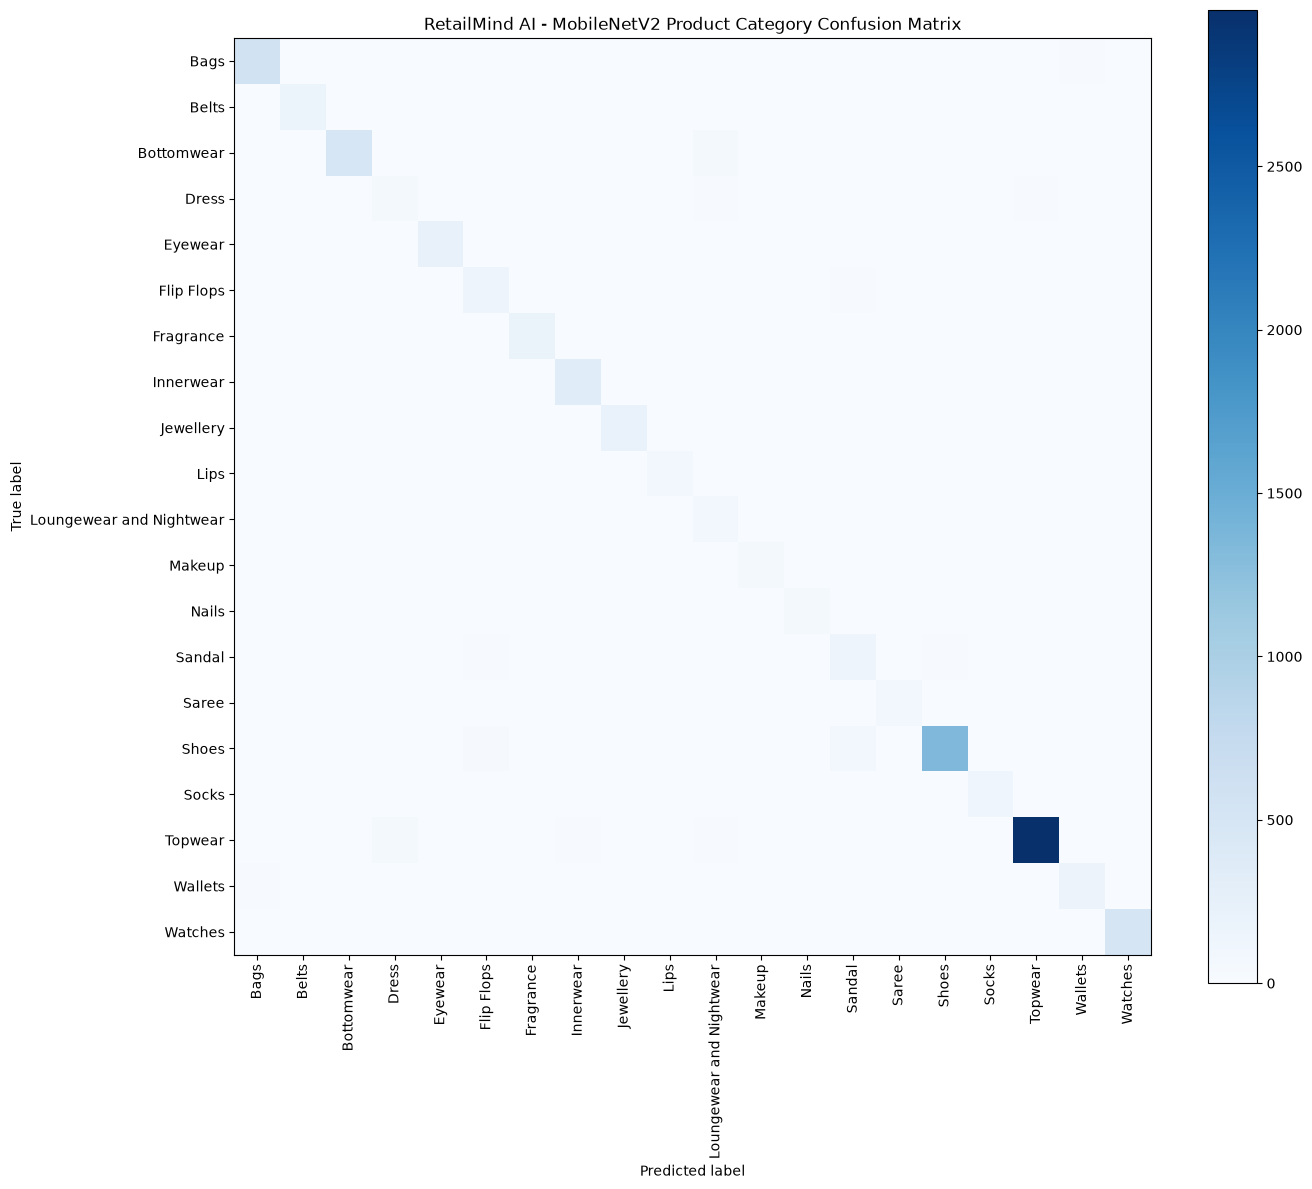

                          precision    recall  f1-score   support

                    Bags       0.96      0.94      0.95       611
                   Belts       0.96      0.96      0.96       162
              Bottomwear       0.98      0.90      0.93       539
                   Dress       0.53      0.67      0.59        95
                 Eyewear       1.00      1.00      1.00       215
              Flip Flops       0.73      0.83      0.78       183
               Fragrance       0.87      0.95      0.91       202
               Innerwear       0.95      0.93      0.94       362
               Jewellery       0.92      0.96      0.94       216
                    Lips       0.95      0.80      0.87       105
Loungewear and Nightwear       0.51      0.89      0.65        94
                  Makeup       0.75      0.85      0.80        61
                   Nails       0.93      0.98      0.96        66
                  Sandal       0.57      0.78      0.66       193
         

In [11]:
class_ids = np.arange(len(class_names))
confusion = confusion_matrix(true_labels, predicted_labels, labels=class_ids)

matrix_display = ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(14, 12))
matrix_display.plot(
    ax=ax,
    include_values=False,
    xticks_rotation="vertical",
    cmap="Blues",
    colorbar=True
)
ax.set_title("RetailMind AI - MobileNetV2 Product Category Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    true_labels,
    predicted_labels,
    labels=class_ids,
    target_names=class_names,
    zero_division=0
))

In [12]:
transfer_model.save(MODEL_PATH)

CLASS_NAMES_PATH = MODEL_DIR / "retailmind_transfer_classes.json"
METRICS_PATH = MODEL_DIR / "retailmind_transfer_metrics.json"

with open(CLASS_NAMES_PATH, "w", encoding="utf-8") as file:
    json.dump(class_names, file, indent=4)

metrics = {
    "project": "RetailMind AI",
    "module": "Day 7 - MobileNetV2 Transfer Learning Classifier",
    "architecture": "MobileNetV2",
    "pretrained_weights": "ImageNet",
    "label_column": LABEL_COLUMN,
    "image_size": list(IMAGE_SIZE),
    "number_of_classes": len(class_names),
    "class_names": class_names,
    "training_images": int(len(train_df)),
    "validation_images": int(len(validation_df)),
    "test_images": int(len(test_df)),
    "test_loss": test_loss,
    "test_accuracy": float(transfer_accuracy),
    "day6_baseline_accuracy": None
}

with open(METRICS_PATH, "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4)

print("Model saved to:", MODEL_PATH)
print("Class names saved to:", CLASS_NAMES_PATH)
print("Metrics saved to:", METRICS_PATH)

Model saved to: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\cv\retailmind_transfer_learning.keras
Class names saved to: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\cv\retailmind_transfer_classes.json
Metrics saved to: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\cv\retailmind_transfer_metrics.json


In [13]:
DAY6_METRICS_PATH = MODEL_DIR / "retailmind_catalog_metrics.json"
day6_accuracy = None
comparison_note = "Day 6 baseline is not available yet. Train Day 6 and rerun this cell to complete the comparison."

if DAY6_METRICS_PATH.is_file():
    try:
        with open(DAY6_METRICS_PATH, "r", encoding="utf-8") as file:
            day6_metrics = json.load(file)

        same_classes = day6_metrics.get("class_names") == class_names
        same_label_column = day6_metrics.get("label_column") == LABEL_COLUMN
        same_test_size = day6_metrics.get("test_images") == len(test_df)

        if same_classes and same_label_column and same_test_size:
            day6_accuracy = float(day6_metrics["catalog_test_accuracy"])
            difference = transfer_accuracy - day6_accuracy
            comparison_note = (
                f"MobileNetV2 is {abs(difference):.2%} "
                f"{'higher' if difference >= 0 else 'lower'} than the Day 6 CNN."
            )
        else:
            comparison_note = (
                "Day 6 metrics were found, but the categories or test-set size do not match. "
                "Check that both notebooks use the same dataset and settings."
            )
    except (KeyError, TypeError, ValueError, json.JSONDecodeError) as error:
        comparison_note = f"Day 6 metrics could not be used for comparison: {error}"

print(f"Day 6 CNN accuracy: {day6_accuracy if day6_accuracy is not None else 'Pending'}")
print(f"Day 7 MobileNetV2 accuracy: {transfer_accuracy:.4f}")
print(comparison_note)

metrics["day6_baseline_accuracy"] = day6_accuracy
metrics["comparison"] = comparison_note
with open(METRICS_PATH, "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4)

README_PATH = PROJECT_DIR / "README.md"
README_HEADING = "## Day 7 - Transfer Learning Classifier"
if day6_accuracy is None:
    day6_readme_line = "- Day 6 CNN baseline accuracy: Pending"
    comparison_readme_line = "- Comparison: Pending until the Day 6 model is trained"
else:
    day6_readme_line = f"- Day 6 CNN baseline test accuracy: {day6_accuracy:.2%}"
    comparison_readme_line = f"- Accuracy difference: {transfer_accuracy - day6_accuracy:+.2%}"

readme_section = (
    f"{README_HEADING}\n\n"
    f"- Architecture: MobileNetV2 with ImageNet pretrained weights\n"
    f"- Product categories: {len(class_names)}\n"
    f"- Label column: `{LABEL_COLUMN}`\n"
    f"- Day 7 test accuracy: {transfer_accuracy:.2%}\n"
    f"{day6_readme_line}\n"
    f"{comparison_readme_line}\n"
    f"- Saved model: `{MODEL_PATH.relative_to(PROJECT_DIR)}`\n"
)

if README_PATH.exists():
    readme_text = README_PATH.read_text(encoding="utf-8")
else:
    readme_text = "# RetailMind AI\n"

section_pattern = re.compile(
    r"(?ms)^## Day 7 - Transfer Learning Classifier\n.*?(?=^## |\Z)"
)

if section_pattern.search(readme_text):
    readme_text = section_pattern.sub(readme_section, readme_text).rstrip() + "\n"
else:
    readme_text = readme_text.rstrip() + "\n\n" + readme_section

README_PATH.write_text(readme_text, encoding="utf-8")
print("README updated:", README_PATH)
print(readme_section)

Day 6 CNN accuracy: Pending
Day 7 MobileNetV2 accuracy: 0.9356
Day 6 baseline is not available yet. Train Day 6 and rerun this cell to complete the comparison.
README updated: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\README.md
## Day 7 - Transfer Learning Classifier

- Architecture: MobileNetV2 with ImageNet pretrained weights
- Product categories: 20
- Label column: `subCategory`
- Day 7 test accuracy: 93.56%
- Day 6 CNN baseline accuracy: Pending
- Comparison: Pending until the Day 6 model is trained
- Saved model: `models\cv\retailmind_transfer_learning.keras`



In [ ]:
print("Day 7 completed")
print(f"MobileNetV2 test accuracy: {transfer_accuracy:.2%}")
print("Saved model:", MODEL_PATH)
print("README:", README_PATH)
if day6_accuracy is None:
    print("Run the Day 6 notebook first, then rerun the comparison and README cell to record the baseline comparison.")